# 01 — Explorer le grand livre

**Objectif :** comprendre les données AVANT de chercher des fraudes. Un auditeur commence toujours par là.

Réponds à chaque question dans la cellule de code en dessous, puis écris ta réponse en une phrase dans une cellule de texte.
Les premières cellules sont remplies pour te mettre le pied à l'étrier.

> Avant de lancer ce carnet : `python -m anomalies.generate` (depuis la racine du projet) doit avoir créé `data/fec.csv`.

In [2]:
import sys
sys.path.append("..")  # pour pouvoir importer le dossier anomalies/ depuis notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anomalies.ecritures import charger_fec, resumer_ecritures

fec = charger_fec("../data/fec.csv")
print(fec.shape)
fec.head(10)

(110004, 20)


,JournalCode,JournalLib,EcritureNum,EcritureDate,CompteNum,CompteLib,CompAuxNum,CompAuxLib,PieceRef,PieceDate,EcritureLib,Debit,Credit,EcritureLet,DateLet,ValidDate,Montantdevise,Idevise,Utilisateur,Validateur
0,AC,Achats,AC000001,2025-01-01,622600,Honoraires,,,FA000594,2025-01-01,Facture fournisseur F044,1427.60,0.00,,,2025-01-03,,,amartin,glaurent
1,AC,Achats,AC000001,2025-01-01,445660,TVA déductible sur ABS,,,FA000594,2025-01-01,Facture fournisseur F044,285.52,0.00,,,2025-01-03,,,amartin,glaurent
2,AC,Achats,AC000001,2025-01-01,401000,Fournisseurs,F044,F044,FA000594,2025-01-01,Facture fournisseur F044,0.00,1713.12,,,2025-01-03,,,amartin,glaurent
3,AC,Achats,AC000002,2025-01-01,607000,Achats de marchandises,,,FA000887,2025-01-01,Facture fournisseur F072,426.36,0.00,,,2025-01-06,,,amartin,glaurent
4,AC,Achats,AC000002,2025-01-01,445660,TVA déductible sur ABS,,,FA000887,2025-01-01,Facture fournisseur F072,85.27,0.00,,,2025-01-06,,,amartin,glaurent
5,AC,Achats,AC000002,2025-01-01,401000,Fournisseurs,F072,F072,FA000887,2025-01-01,Facture fournisseur F072,0.00,511.63,,,2025-01-06,,,amartin,glaurent
6,AC,Achats,AC000003,2025-01-01,607000,Achats de marchandises,,,FA001135,2025-01-01,Facture fournisseur F030,57.63,0.00,,,2025-01-01,,,amartin,glaurent
7,AC,Achats,AC000003,2025-01-01,445660,TVA déductible sur ABS,,,FA001135,2025-01-01,Facture fournisseur F030,11.52,0.00,,,2025-01-01,,,amartin,glaurent
8,AC,Achats,AC000003,2025-01-01,401000,Fournisseurs,F030,F030,FA001135,2025-01-01,Facture fournisseur F030,0.00,69.15,,,2025-01-01,,,amartin,glaurent
9,AC,Achats,AC000004,2025-01-01,613200,Locations immobilières,,,FA001139,2025-01-01,Facture fournisseur F003,860.77,0.00,,,2025-01-03,,,dleroy,fsimon


## 1. Lire une écriture
Affiche toutes les lignes de l'écriture `AC000001`. Combien de lignes ? Quels comptes ? Vérifie à la main que débit = crédit.

In [3]:
fec[fec["EcritureNum"] == "AC000001"]

,JournalCode,JournalLib,EcritureNum,EcritureDate,CompteNum,CompteLib,CompAuxNum,CompAuxLib,PieceRef,PieceDate,EcritureLib,Debit,Credit,EcritureLet,DateLet,ValidDate,Montantdevise,Idevise,Utilisateur,Validateur
0,AC,Achats,AC000001,2025-01-01,622600,Honoraires,,,FA000594,2025-01-01,Facture fournisseur F044,1427.60,0.00,,,2025-01-03,,,amartin,glaurent
1,AC,Achats,AC000001,2025-01-01,445660,TVA déductible sur ABS,,,FA000594,2025-01-01,Facture fournisseur F044,285.52,0.00,,,2025-01-03,,,amartin,glaurent
2,AC,Achats,AC000001,2025-01-01,401000,Fournisseurs,F044,F044,FA000594,2025-01-01,Facture fournisseur F044,0.00,1713.12,,,2025-01-03,,,amartin,glaurent


## 2. Le FEC est-il équilibré ?
Pour CHAQUE écriture, la somme des débits doit égaler la somme des crédits. Vérifie-le en une ou deux lignes (`groupby`, `sum`, `round(2)`).
Puis vérifie aussi que le total général des débits = total général des crédits.

In [4]:
totaux = fec.groupby("EcritureNum")[["Debit", "Credit"]].sum().round(2)
(totaux.Debit == totaux.Credit).all()

np.True_

## 3. Passer au niveau « écriture »
La fonction `resumer_ecritures` donne une ligne par écriture. Lis son code dans `anomalies/ecritures.py`, puis crée le tableau `ecritures`.

In [5]:
ecritures = resumer_ecritures(fec)
ecritures.head()

,EcritureNum,JournalCode,EcritureDate,ValidDate,PieceRef,Utilisateur,Validateur,montant,tiers,comptes,nb_lignes
0,AC000001,AC,2025-01-01,2025-01-03,FA000594,amartin,glaurent,1713.12,F044,401000 445660 622600,3
1,AC000002,AC,2025-01-01,2025-01-06,FA000887,amartin,glaurent,511.63,F072,401000 445660 607000,3
2,AC000003,AC,2025-01-01,2025-01-01,FA001135,amartin,glaurent,69.15,F030,401000 445660 607000,3
3,AC000004,AC,2025-01-01,2025-01-03,FA001139,dleroy,fsimon,1032.92,F003,401000 445660 613200,3
4,AC000005,AC,2025-01-01,2025-01-02,FA002478,emoreau,glaurent,57.53,F045,401000 445660 613200,3


## 4. Combien d'écritures par journal ?
Indice : `value_counts()`. Lequel est le plus gros ? Pourquoi, d'après toi ?

In [6]:
df = pd.DataFrame({"nb_lignes":fec["JournalCode"].value_counts(),
                    "nb_écritures":ecritures["JournalCode"].value_counts()})
df["lignes_par_ecriture"] = (df["nb_lignes"] / df["nb_écritures"]).round(2)

df.sort_values(by="nb_écritures", ascending=False)

,nb_lignes,nb_écritures,lignes_par_ecriture
JournalCode,,,
BQ,34770,17385,2.00
VE,37653,12551,3.00
AC,37452,12484,3.00
OD,129,47,2.74


Les écritures de banque sont les plus nombreuses,
pourtant le nombre de lignes des écritures de Banque sont plus faibles que celui des ventes et des achats.
Cependant, il y a une écriture quand le client et EY paye une facture chacun, **donc BQ regroupe deux flux quand VE, AC et OD en ont un seul.**

## 5. L'activité au fil de l'année
Trace le nombre d'écritures par mois (indice : `ecritures["EcritureDate"].dt.month`, puis `.value_counts().sort_index().plot(kind="bar")`).
Quel mois est le plus calme ? Le plus chargé ?

Text(0, 0.5, "Nombre d'écritures")

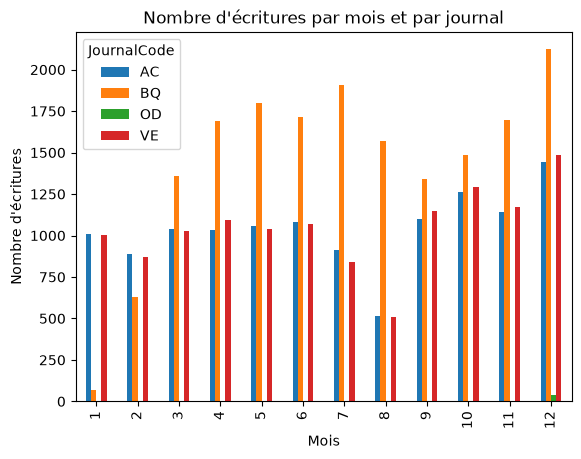

In [7]:
tableau_mensuel = pd.crosstab(ecritures["EcritureDate"].dt.month, 
                              ecritures["JournalCode"])

ax = tableau_mensuel.plot(kind="bar", 
                          title="Nombre d'écritures par mois et par journal")
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre d'écritures")

Le mois le plus chargé est le mois de décembre, lié au fameux rush de fin d'an.
Logiquement, le mois de janvier est plus calme, nous remarquons une baisse en août qui peut être liée aux congés.
Les achats et ventes sont beaucoup plus constants que les transactions avec la banque, mais cette différence ne se constate que très significativement sur les mois de janvier et décembre. Cela pourrait s'expliquer par un événement X lié aux banques en fin d'année.

## 6. À quoi ressemblent les montants ?
1. Affiche `ecritures["montant"].describe()`. La moyenne et la médiane sont-elles proches ? Qu'est-ce que ça t'apprend ?
2. Trace un histogramme des montants, puis un histogramme de `np.log10(montant)`. Lequel est le plus lisible ? Pourquoi ?

In [8]:
ecritures["montant"].describe()

count     42467.000000
mean       2873.972883
std        5770.422409
min           9.880000
25%         503.380000
50%        1185.200000
75%        2928.490000
max      224953.300000
Name: montant, dtype: float64

La moyenne est bien au dessus de la médiane donc il y a des valeurs très grandes

<Axes: ylabel='Frequency'>

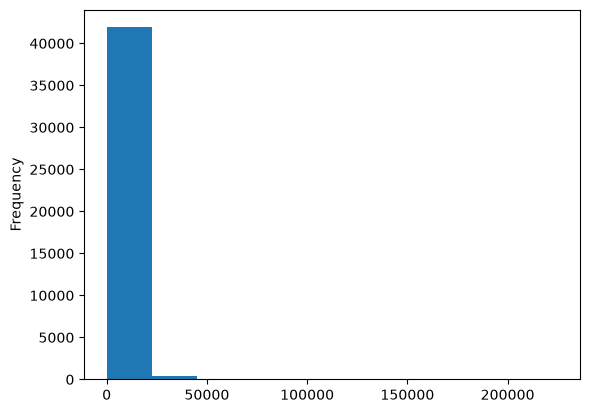

In [9]:
ecritures["montant"].plot(kind="hist")

<Axes: ylabel='Frequency'>

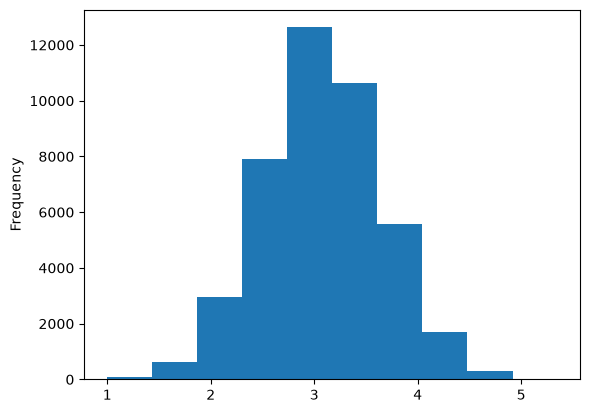

In [10]:
m = ecritures["montant"]
m = m[m > 0]
np.log10(m).plot(kind="hist")

Ce graphique est plus lisible car il montre mieux la dispersion des instances. On voit bien le pic en 10^3 qui est cohérent avec la médiane.

## 7. Qui saisit, qui valide ?
Fais un tableau croisé `pd.crosstab(ecritures["Utilisateur"], ecritures["Validateur"])`.
Est-ce que quelque chose te surprend ? (Indice : regarde les lignes des personnes qui ne sont pas comptables.)

In [11]:
pd.crosstab(ecritures["Utilisateur"], ecritures["Validateur"])

Validateur,amartin,bdurand,cpetit,dleroy,emoreau,fsimon,glaurent
Utilisateur,,,,,,,
amartin,9,0,0,0,0,4241,4298
bdurand,0,7,0,0,0,4220,4227
cpetit,0,0,9,0,0,4229,4168
dleroy,0,0,0,6,0,4199,4267
emoreau,0,0,0,0,4,4283,4265
fsimon,0,0,0,0,0,0,23
glaurent,0,0,0,0,0,12,0


D'abord, la diagonale devrait être nulle car une personne ne devrait pas saisir et valider en même temps. De plus, on remarque que fsimon et glaurent ne sont pas comptables or ils ont validés 23 et 12 opérations entre eux.

## 8. Les plus gros fournisseurs
Pour le journal des achats (`AC`), calcule le montant total par `tiers` et affiche les 10 plus gros.

In [12]:
achats = ecritures[ecritures["JournalCode"] == "AC"]
achats.groupby("tiers")["montant"].sum().sort_values(ascending=False).head(10)


tiers
F035    692307.66
F064    645850.89
F051    608079.34
F033    606485.04
F015    590127.94
F003    559876.69
F074    545910.09
F066    542159.63
F047    541895.89
F012    541788.20
Name: montant, dtype: float64

## 9. Ton intuition d'auditeur
Sans regarder `verite_terrain.csv` : liste 3 choses que tu trouverais suspectes dans un grand livre, et comment tu les repérerais en pandas.
Tu compareras avec les règles de l'étape 3.

Au long de cette étude, j'ai repéré plusieurs choses suspectes :
- Un nombre important de transactions OD manuelles en fin décembre, pour gonfler le chiffre d'affaire (filtrer le journal OD le mois 12)
- Une transaction d'un compte réalisées à quelques jours d'interval, ou juste sous le seuil d'approbation, possible tentative de fraude en fractionnement (afficher les transactions proche du seuil d'approbation ou pour un même compte avec des dates proches)
- Des comptables qui saisissent des opérations et les valident eux-mêmes, des responsables qui saisissent des opérations, des opérations réalisées en jour férié ou weekend (tableau croisé utilisateur / validateur, afficher les transactions faites sur un samedi/dimanche )

## Tests benford.py

In [13]:
from anomalies.benford import premier_chiffre

chiffres = premier_chiffre(ecritures["montant"])
chiffres.head()

0    1
1    5
2    6
3    1
4    5
Name: montant, dtype: int64

In [14]:
from anomalies.benford import frequences_benford

A = frequences_benford()
print(A)

1    0.301030
2    0.176091
3    0.124939
4    0.096910
5    0.079181
6    0.066947
7    0.057992
8    0.051153
9    0.045757
dtype: float64


In [15]:
from anomalies.benford import analyse_benford

d = analyse_benford(ecritures["montant"])
d["mad"], d["conclusion"]

(np.float64(0.001963294319411213), 'conformité forte')